# Replay one experimental game

This notebook replays one Choi 2020 game and shows:

- the replay setup in separate stages
- the actions printed per step
- the directed graph after each recorded state
- multiple replay metrics plotted from a list of observers


## Imports


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scienceplots

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from network_creation.core.observability import ObservationSampling
from network_creation.data.choi_2020 import (build_replay_simulator,
                                             list_choi_2020_configs,
                                             load_choi_2020_normalized_data,
                                             run_choi_2020_replay_batch)
from network_creation.observers.grimoire import OBSERVER_GRIMOIRE
from network_creation.plotting.episode_series import \
    plot_episode_series_observer
from network_creation.plotting.graph_history import (
    build_circle_layout,
    plot_graph_history,
)

ActionCountObserver = OBSERVER_GRIMOIRE["action_count"]
ActionPrintObserver = OBSERVER_GRIMOIRE["action_print"]
DensityObserver = OBSERVER_GRIMOIRE["density"]
DistanceObserver = OBSERVER_GRIMOIRE["distance"]
GlobalClosenessCentralityObserver = OBSERVER_GRIMOIRE["global_closeness_centrality"]
IndegreeObserver = OBSERVER_GRIMOIRE["indegree"]
StateHistoryObserver = OBSERVER_GRIMOIRE["state_history"]
HubPersistenceObserver = OBSERVER_GRIMOIRE["hub_persistence"]
CentralPointOfDominanceObserver = OBSERVER_GRIMOIRE["central_point_of_dominance"]
TriadCensusObserver = OBSERVER_GRIMOIRE["triad_census"]
NormalizedWelfareObserver = OBSERVER_GRIMOIRE["normalized_welfare"]


In [2]:
plt.style.use(style="science")

In [3]:
benefit_to_cost_ratio, distance_discount = 0.5, 0.9

## Replay data


In [4]:
data_root = project_root / "data/choi_2020/raw"
available_configs = list_choi_2020_configs(data_root)
available_configs[:5]

(Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=2, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=3, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=4, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=5, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=6, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')))

In [5]:
config = available_configs[0]
max_steps = load_choi_2020_normalized_data(config).max_step
config, max_steps

(Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=2, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 359)

## Observer settings


In [6]:
action_printer = ActionPrintObserver(observation_sampling=ObservationSampling.periodic(1), print_empty_steps=False)
metric_observers = [
    DensityObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=()),
    IndegreeObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=()),
    GlobalClosenessCentralityObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=()),
    DistanceObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=()),
    ActionCountObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=()),
    HubPersistenceObserver(observation_sampling=ObservationSampling.periodic(1), window_size=10, aggregations=()),
    CentralPointOfDominanceObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=()),
    TriadCensusObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=()),
    NormalizedWelfareObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=(), benefit_to_cost_ratio=benefit_to_cost_ratio, distance_discount=distance_discount),
]
state_history_observer = StateHistoryObserver(observation_sampling=ObservationSampling.periodic(1), keep_runs=False)

(
    action_printer.__class__.__name__,
    [observer.__class__.__name__ for observer in metric_observers],
    state_history_observer.__class__.__name__,
)


('ActionPrintObserver',
 ['DensityObserver',
  'IndegreeObserver',
  'GlobalClosenessCentralityObserver',
  'DistanceObserver',
  'ActionCountObserver',
  'HubPersistenceObserver',
  'CentralPointOfDominanceObserver',
  'TriadCensusObserver',
  'NormalizedWelfareObserver'],
 'StateHistoryObserver')

## Build the replay simulator


In [7]:
simulator = build_replay_simulator(
    config=config,
    observers=(action_printer, *metric_observers, state_history_observer),
    max_steps=max_steps,
)

fixed_layout = build_circle_layout(simulator.n_agents)


## Run the replay


In [8]:
simulator.run(n_episodes=1, reset_observers=False)

(
    simulator.n_completed_episodes,
    state_history_observer.steps[-1],
    {observer.__class__.__name__: observer.steps[-1] for observer in metric_observers},
)



step 6
  8: ADD->2

step 7
  2: ADD->4
  3: ADD->5
  6: ADD->4
  8: ADD->3, ADD->4

step 8
  1: ADD->5
  2: ADD->7

step 9
  5: ADD->7
  7: ADD->0
  8: ADD->6
  9: ADD->8

step 10
  8: ADD->0

step 11
  4: ADD->8
  6: DELETE->4

step 12
  1: ADD->4

step 13
  1: DELETE->5
  7: DELETE->0

step 14
  2: DELETE->7, ADD->8

step 15
  2: DELETE->8
  5: ADD->8

step 16
  2: ADD->9

step 17
  5: DELETE->7

step 18
  2: DELETE->9
  3: DELETE->5
  8: ADD->7

step 19
  1: ADD->8
  2: DELETE->4

step 20
  1: DELETE->4
  2: ADD->7

step 22
  2: DELETE->7

step 23
  2: ADD->6

step 24
  9: ADD->4, DELETE->8

step 26
  2: DELETE->6

step 28
  8: ADD->9

step 31
  3: ADD->7
  5: ADD->9

step 32
  3: DELETE->7
  5: DELETE->8

step 34
  5: ADD->8

step 35
  3: ADD->8
  5: DELETE->9

step 36
  2: ADD->5

step 37
  2: DELETE->5

step 39
  2: ADD->1
  3: DELETE->8

step 40
  2: DELETE->1

step 41
  2: ADD->0
  8: DELETE->4

step 42
  2: DELETE->0

step 43
  2: ADD->7
  5: ADD->2

step 44
  2: DELETE->7
  

(1,
 np.int64(359),
 {'DensityObserver': np.int64(359),
  'IndegreeObserver': np.int64(359),
  'GlobalClosenessCentralityObserver': np.int64(359),
  'DistanceObserver': np.int64(359),
  'ActionCountObserver': np.int64(359),
  'HubPersistenceObserver': np.int64(359),
  'CentralPointOfDominanceObserver': np.int64(359),
  'TriadCensusObserver': np.int64(359),
  'NormalizedWelfareObserver': np.int64(359)})

In [9]:
metric_observers[-1].values[:25]

array([0.5       , 0.5       , 0.5       , 0.5       , 0.5       ,
       0.5       , 0.4994737 , 0.5331216 , 0.5729441 , 0.62562895,
       0.6237384 , 0.62326473, 0.6213316 , 0.62796897, 0.6231426 ,
       0.62882155, 0.6240321 , 0.59339476, 0.63612634, 0.6386842 ,
       0.6386842 , 0.6386842 , 0.6434737 , 0.6386842 , 0.6357    ],
      dtype=float32)

## Directed graph after each recorded state


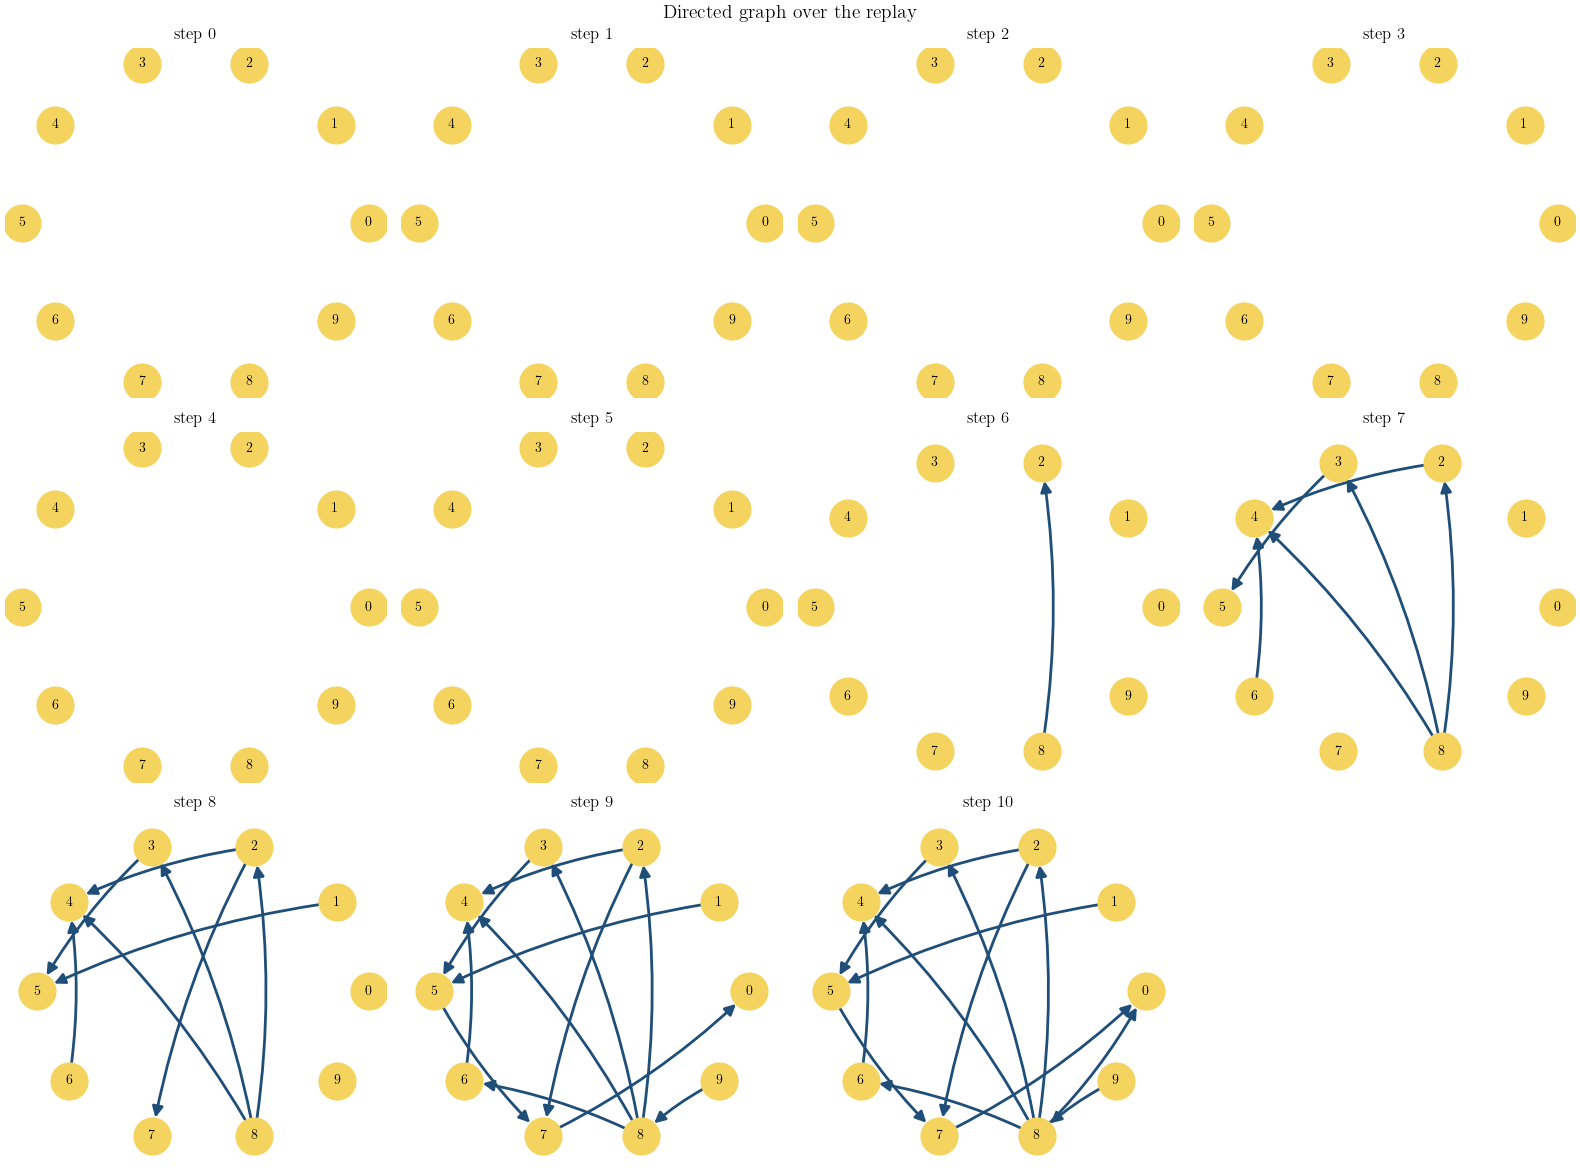

In [10]:
plot_mask = state_history_observer.steps <= 10
plot_graph_history(
    steps=state_history_observer.steps[plot_mask],
    graphs=state_history_observer.graphs[plot_mask],
    layout=fixed_layout,
    figure_title="Directed graph over the replay",
    max_cols=4,
)
plt.show()


## Metrics across the replay


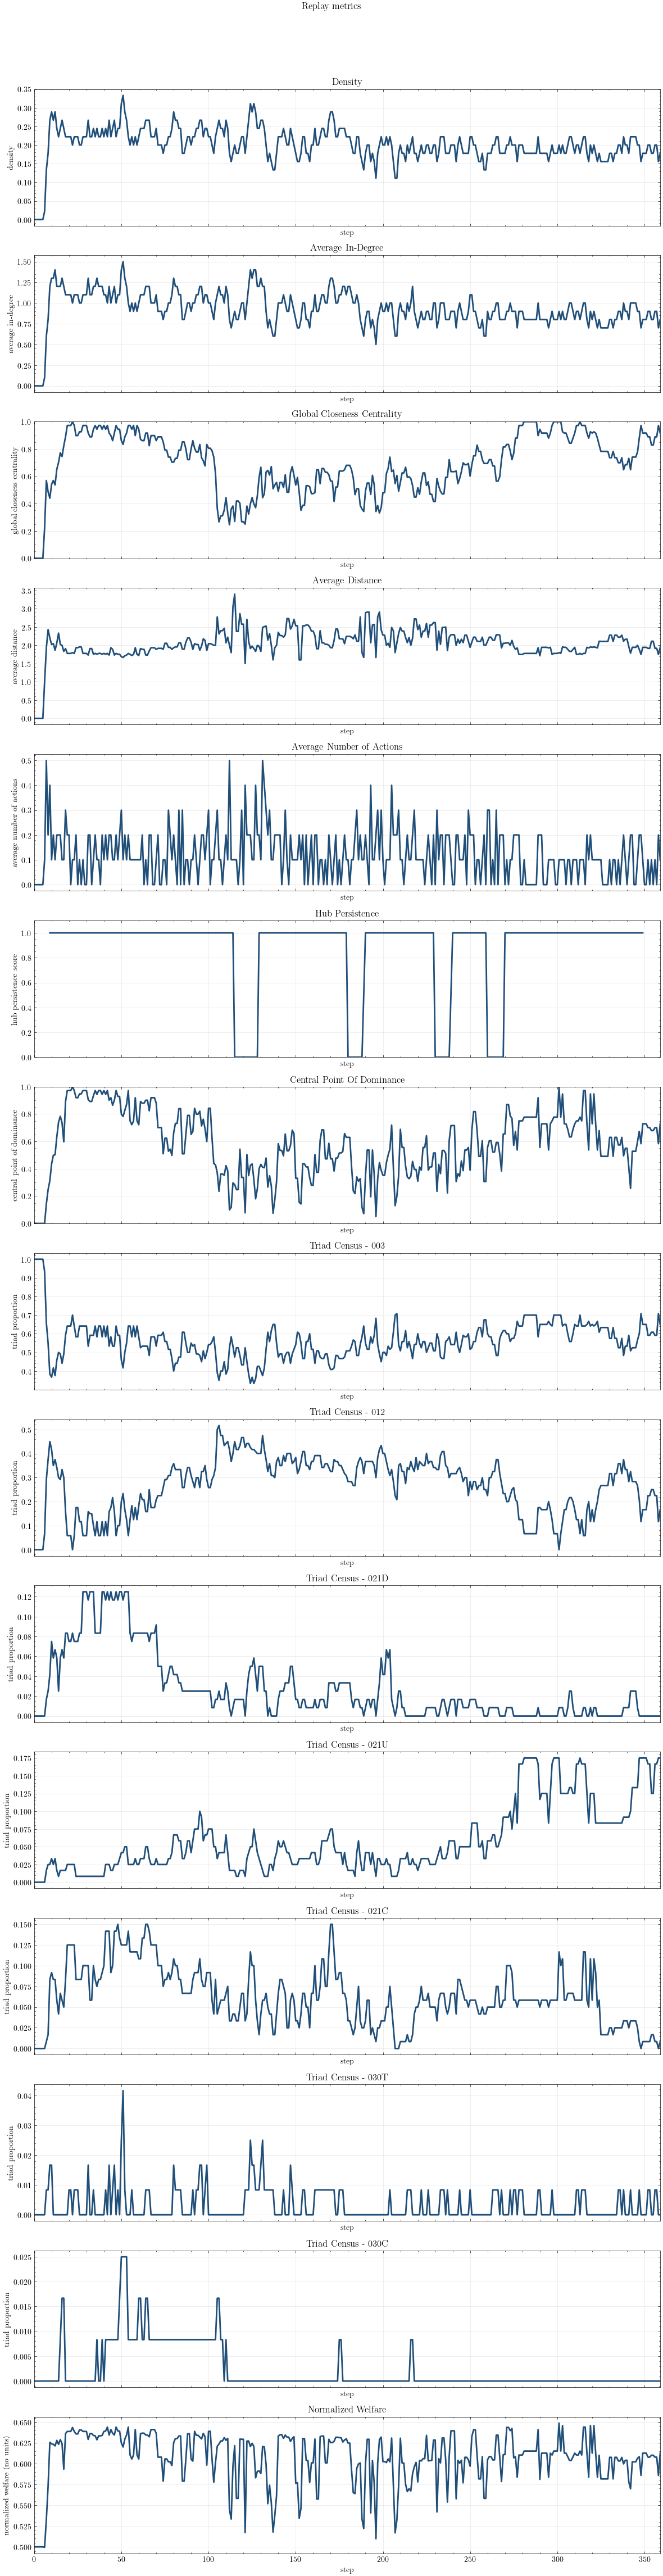

In [11]:
plot_specs = []
for observer in metric_observers:
    if isinstance(observer, TriadCensusObserver):
        plot_specs.extend((observer, dimension_name) for dimension_name in observer.dimension_names)
    else:
        plot_specs.append((observer, None))

figure, axes = plt.subplots(
    len(plot_specs),
    1,
    figsize=(12, 3 * len(plot_specs)),
    squeeze=False,
    sharex=True,
)

for (observer, dimension_name), axis in zip(plot_specs, axes.ravel()):
    plot_episode_series_observer(
        observer=observer,
        ax=axis,
        dimension_name=dimension_name,
        set_title=False,
    )
    axis.set_title(
        observer.label if dimension_name is None else f"{observer.label} - {dimension_name}"
    )

figure.suptitle("Replay metrics", y=1.02)
figure.tight_layout()
plt.show()


## Aggregate metrics across group sizes


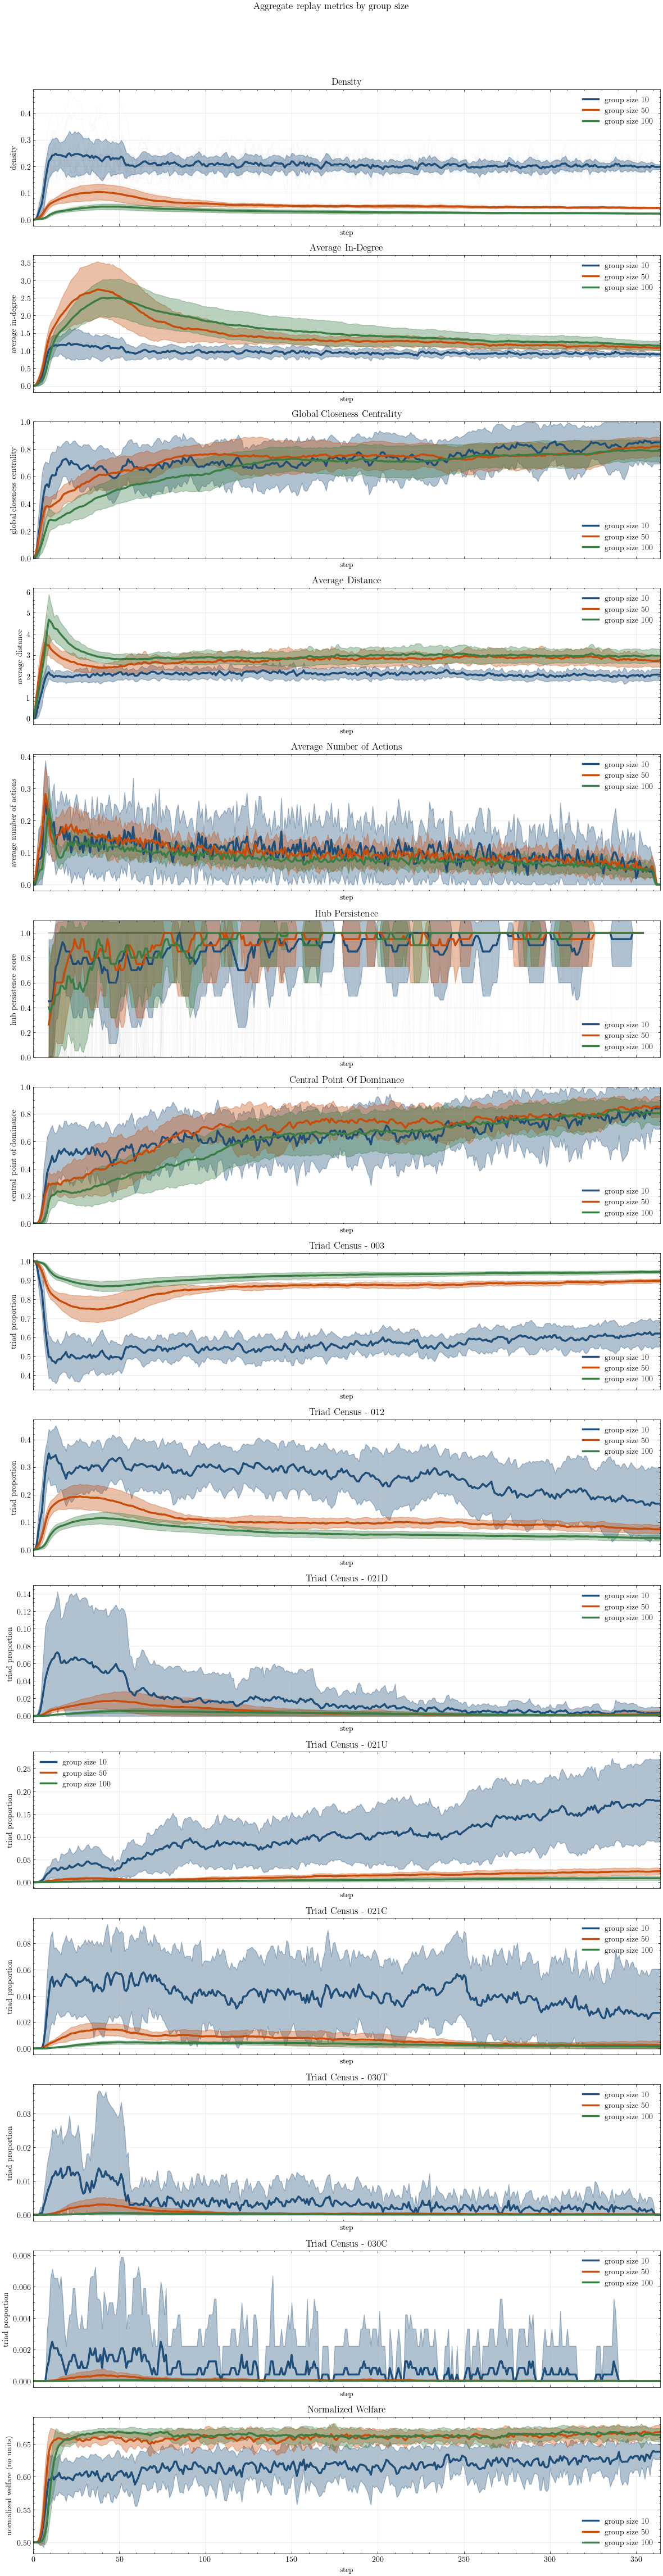

In [12]:
group_sizes = [10, 50, 100]
group_colors = ["#1f4e79", "#c84c09", "#3a7d44"]
metric_observer_builders = [
    lambda _: DensityObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=("mean", "std", "runs")),
    lambda _: IndegreeObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=("mean", "std")),
    lambda _: GlobalClosenessCentralityObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=("mean", "std")),
    lambda _: DistanceObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=("mean", "std")),
    lambda _: ActionCountObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=("mean", "std")),
    lambda _: HubPersistenceObserver(observation_sampling=ObservationSampling.periodic(1), window_size=10, aggregations=("mean", "std", "runs")),
    lambda _: CentralPointOfDominanceObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=("mean", "std")),
    lambda _: TriadCensusObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=("mean", "std")),
    lambda group_size: NormalizedWelfareObserver(observation_sampling=ObservationSampling.periodic(1), aggregations=("mean", "std"), benefit_to_cost_ratio=benefit_to_cost_ratio, distance_discount=distance_discount),
]

max_steps = 364
aggregate_metrics_by_group_size = {}
for group_size in group_sizes:
    group_configs = tuple(
        replay_config
        for replay_config in available_configs
        if replay_config.group_size == group_size
    )
    aggregate_metric_observers = [builder(group_size) for builder in metric_observer_builders]
    run_choi_2020_replay_batch(
        configs=group_configs,
        observers=tuple(aggregate_metric_observers),
        max_steps=max_steps,
    )
    aggregate_metrics_by_group_size[group_size] = aggregate_metric_observers

reference_observers = aggregate_metrics_by_group_size[group_sizes[0]]

plot_specs = []
for metric_idx, observer in enumerate(reference_observers):
    if isinstance(observer, TriadCensusObserver):
        plot_specs.extend((metric_idx, dimension_name) for dimension_name in observer.dimension_names)
    else:
        plot_specs.append((metric_idx, None))

figure, axes = plt.subplots(
    len(plot_specs),
    1,
    figsize=(12, 3 * len(plot_specs)),
    squeeze=False,
    sharex=True,
)

for (metric_idx, dimension_name), axis in zip(plot_specs, axes.ravel()):

    for group_size, color in zip(group_sizes, group_colors):
        observer = aggregate_metrics_by_group_size[group_size][metric_idx]
        plot_episode_series_observer(
            observer=observer,
            ax=axis,
            dimension_name=dimension_name,
            color=color,
            band_color=color,
            label=f"group size {group_size}",
            set_title=False,
            show_runs=True,
        )
    reference_observer_label = reference_observers[metric_idx].label
    axis.set_title(
        reference_observer_label
        if dimension_name is None
        else f"{reference_observer_label} - {dimension_name}"
    )

figure.suptitle("Aggregate replay metrics by group size", y=1.02)
figure.tight_layout()
plt.show()
